[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/06_MLP_Neural_Network.ipynb)

# 06. Neural network: Multi-Layer Perceptron
**Run on:** Laptop B · **Approx. runtime:** ~6-8 min on a 4-core laptop


**Protocol (same for every model):**
- Each row is one *(GPS point, candidate arc)* pair. The label is 1 if the arc is the point's reference arc.
- **5-fold GroupKFold by trip** on the 78 usable training trips. Each fold fits on a 300k-row sample of points (KNN uses 100k) and is scored on all candidates of the held-out trips.
- The model is then **refit on the training split** and scored on the **10 student-test trips**.
- **Metrics:**
  - macro F1 / precision / recall: candidate level, threshold 0.5
  - log loss
  - **Top-1 accuracy**: the share of GPS points whose highest-scoring candidate is the reference arc
  - continuity
- The **HMM/Viterbi** decoder (parameters in `models/hmm_params.json`) is then run on this model's probabilities to compare *classifier only* with *classifier + HMM*.


**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## MLP


**What it does:** a feed-forward network, 14 inputs → 64 ReLU → 32 ReLU → 1 sigmoid output, trained with Adam. Each layer learns non-linear combinations of the previous layer's outputs.
- **Why tried:** a different inductive bias from trees: smooth non-linear boundaries.
- **Limitations:** needs feature scaling, is sensitive to initialisation and learning rate, and is less interpretable.
- **Hyperparameters:** hidden layers (64, 32), alpha (L2) = 1e-4, Adam, early stopping on a 10% validation split, max 200 epochs.
- **Loss:** binary cross-entropy.

In [3]:
make_mlp = lambda: make_model("mlp", SEED)
print(make_mlp())
cv_mlp = nb.run_cv(make_mlp, tr, tr_pts, max_rows=300000)
cv_mlp.round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32),
                               random_state=42))])


  fold 0: F1=0.9123 top1=0.8584 ll=0.1530


  fold 1: F1=0.9266 top1=0.8775 ll=0.1050


  fold 2: F1=0.9167 top1=0.8703 ll=0.1624


  fold 3: F1=0.9476 top1=0.9192 ll=0.0815


  fold 4: F1=0.9087 top1=0.8525 ll=0.1328


CV time 230s | mean macro F1 0.9224 ± 0.0156


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9123,0.8795,0.8333,0.1530,0.8584,0.1857,0.0049,63.6486
1,0.9266,0.8970,0.8533,0.1050,0.8775,0.3342,0.0107,72.7918
2,0.9167,0.8592,0.8784,0.1624,0.8703,0.1783,0.0041,42.7071
3,0.9476,0.9264,0.8992,0.0815,0.9192,0.2021,0.0059,17.3314
4,0.9087,0.8724,0.8221,0.1328,0.8525,0.1799,0.0053,29.8593


In [4]:
model_mlp, train_mlp, test_mlp, p_mlp = nb.fit_and_evaluate(make_mlp, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_mlp['continuity']:.4f} | inference {test_mlp['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("MLP", cv_mlp, train_mlp, test_mlp)

fit 38.0s on 300,108 rows
student-test continuity (classifier only): 0.9310 | inference 0.0054 ms/point


MLP,train (fit sample),CV mean (5 folds),student test
macro F1,0.9331,0.9224,0.9216
precision,0.9060,0.8869,0.8909
recall,0.8729,0.8573,0.8478
log loss,0.1013,0.1269,0.1134
Top-1 accuracy,0.8952,0.8756,0.8807


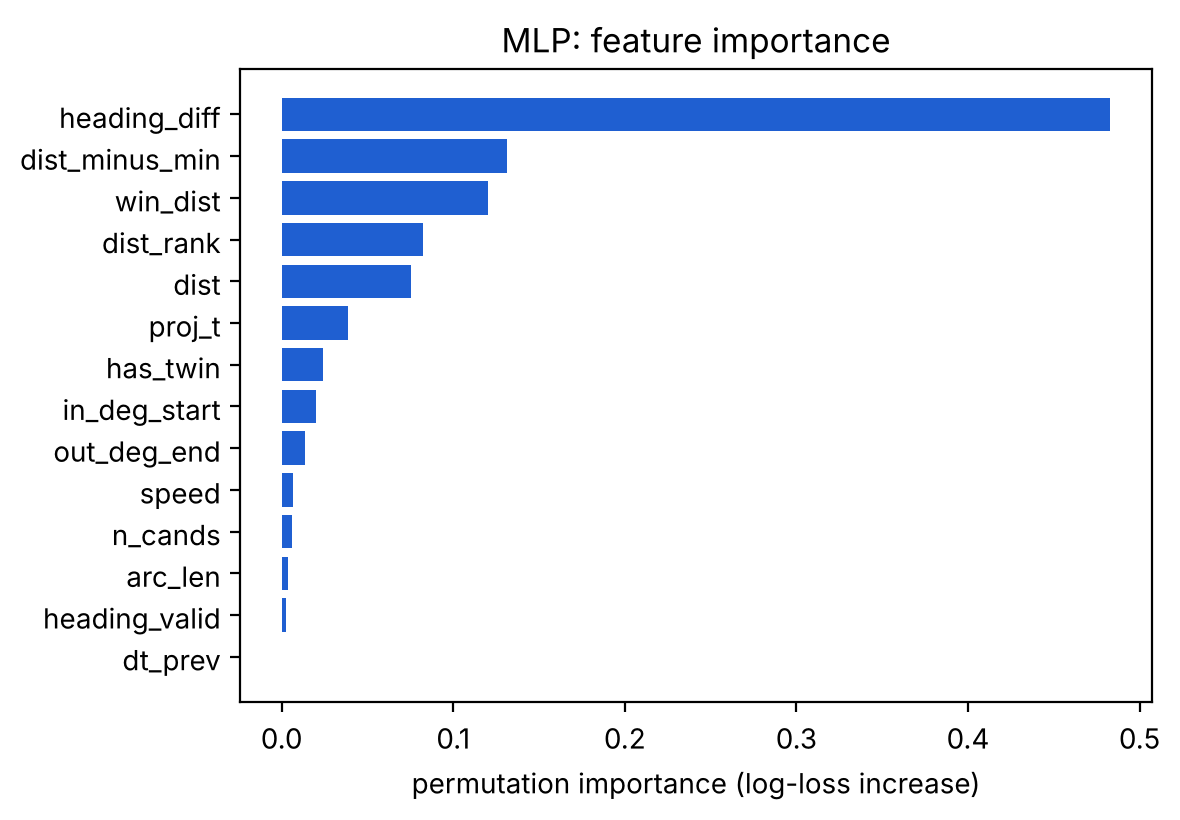

In [5]:
imp_mlp = nb.plot_importance(model_mlp, te, "MLP")

MLP: mean over 10 trips
cls_top1          0.8936
hmm_top1          0.9296
cls_route_f1      0.7859
hmm_route_f1      0.9563
cls_continuity    0.9310
hmm_continuity    0.9766


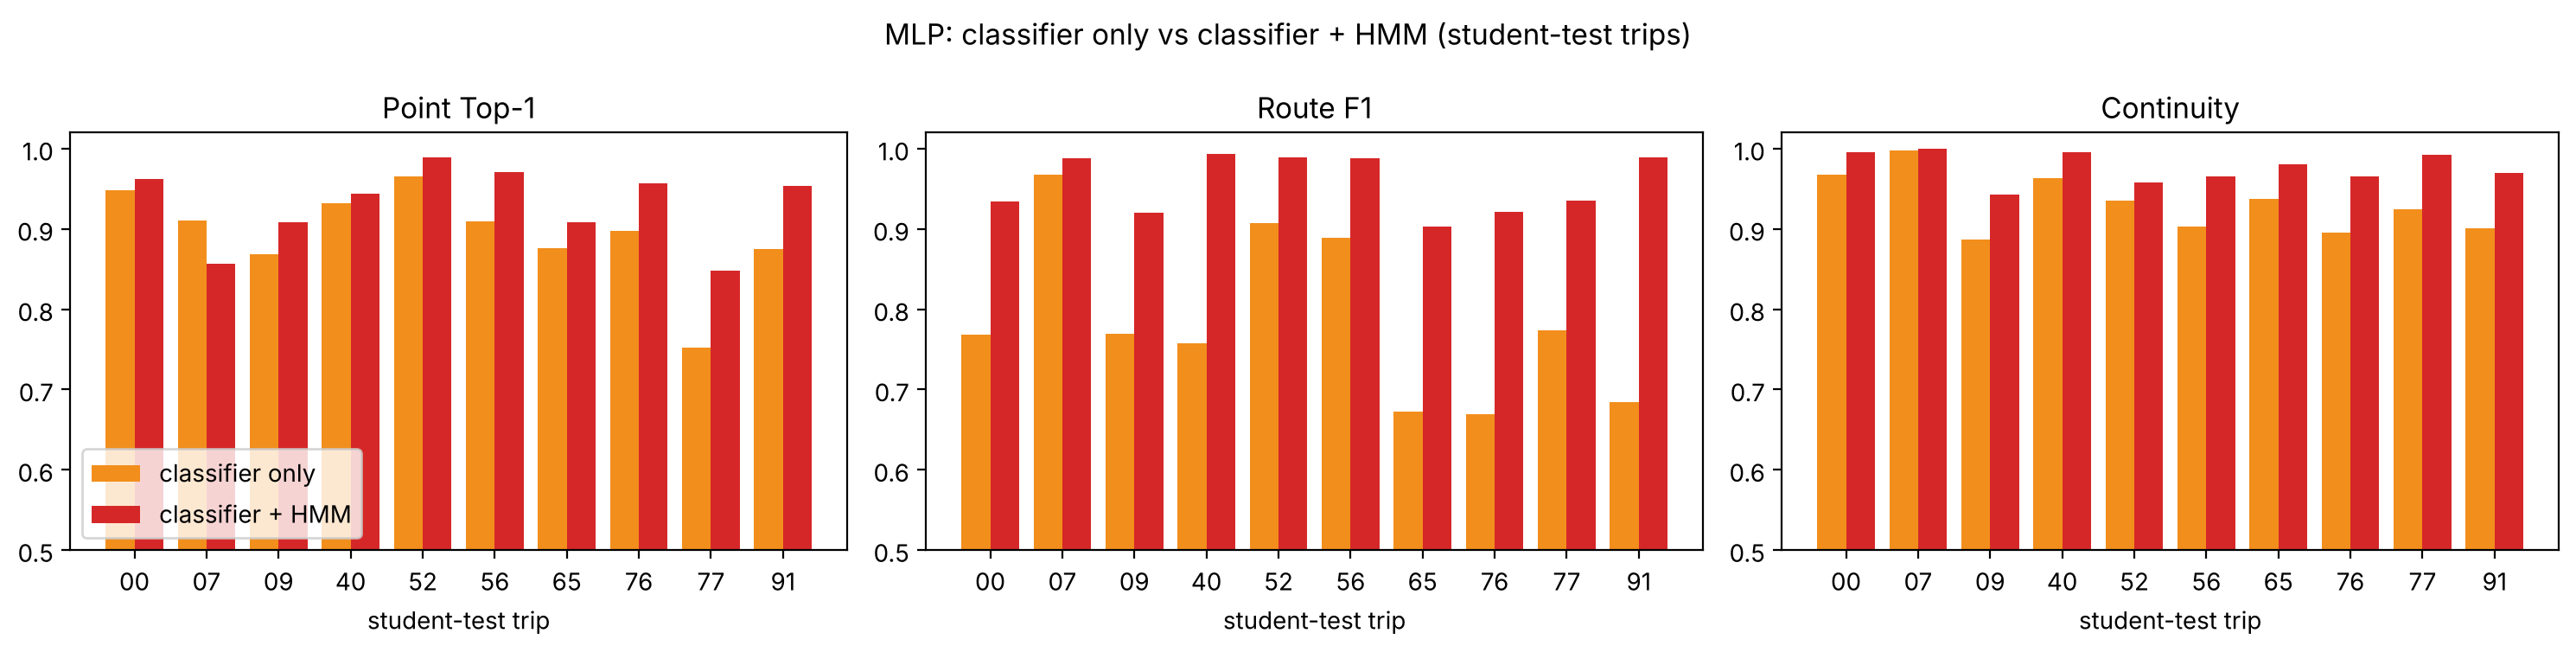

saved results/notebooks/mlp.json


In [6]:
hmm_mlp = nb.hmm_compare(model_mlp, te, "MLP")
nb.plot_hmm(hmm_mlp, "MLP: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("mlp", cv_mlp, train_mlp, test_mlp,
                {"hmm_mean": hmm_mlp.drop(columns=["trip", "model"]).mean().to_dict()})

### Training history (epoch-wise)
The MLP is the only model here that trains in epochs, so it is the only one with a genuine loss curve.

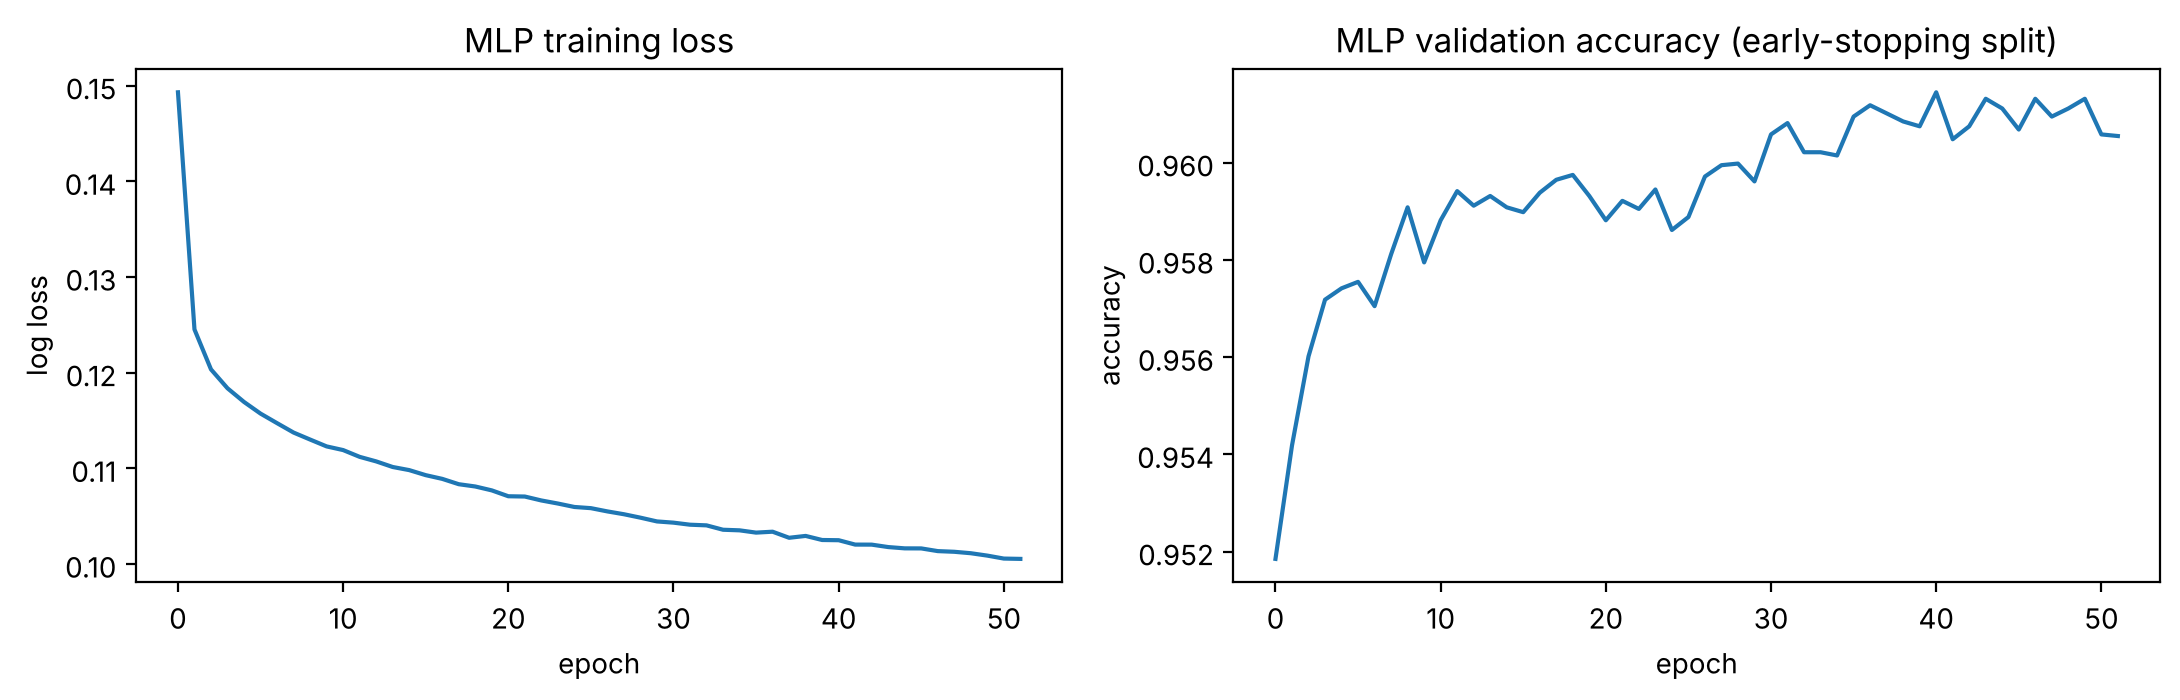

stopped after 52 epochs; best validation accuracy 0.9614


In [7]:
mlp = model_mlp[-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(mlp.loss_curve_); ax[0].set(title="MLP training loss", xlabel="epoch", ylabel="log loss")
ax[1].plot(mlp.validation_scores_); ax[1].set(title="MLP validation accuracy (early-stopping split)", xlabel="epoch", ylabel="accuracy")
fig.tight_layout(); nb.show()
print(f"stopped after {mlp.n_iter_} epochs; best validation accuracy {max(mlp.validation_scores_):.4f}")

## Comparison of the models in this notebook

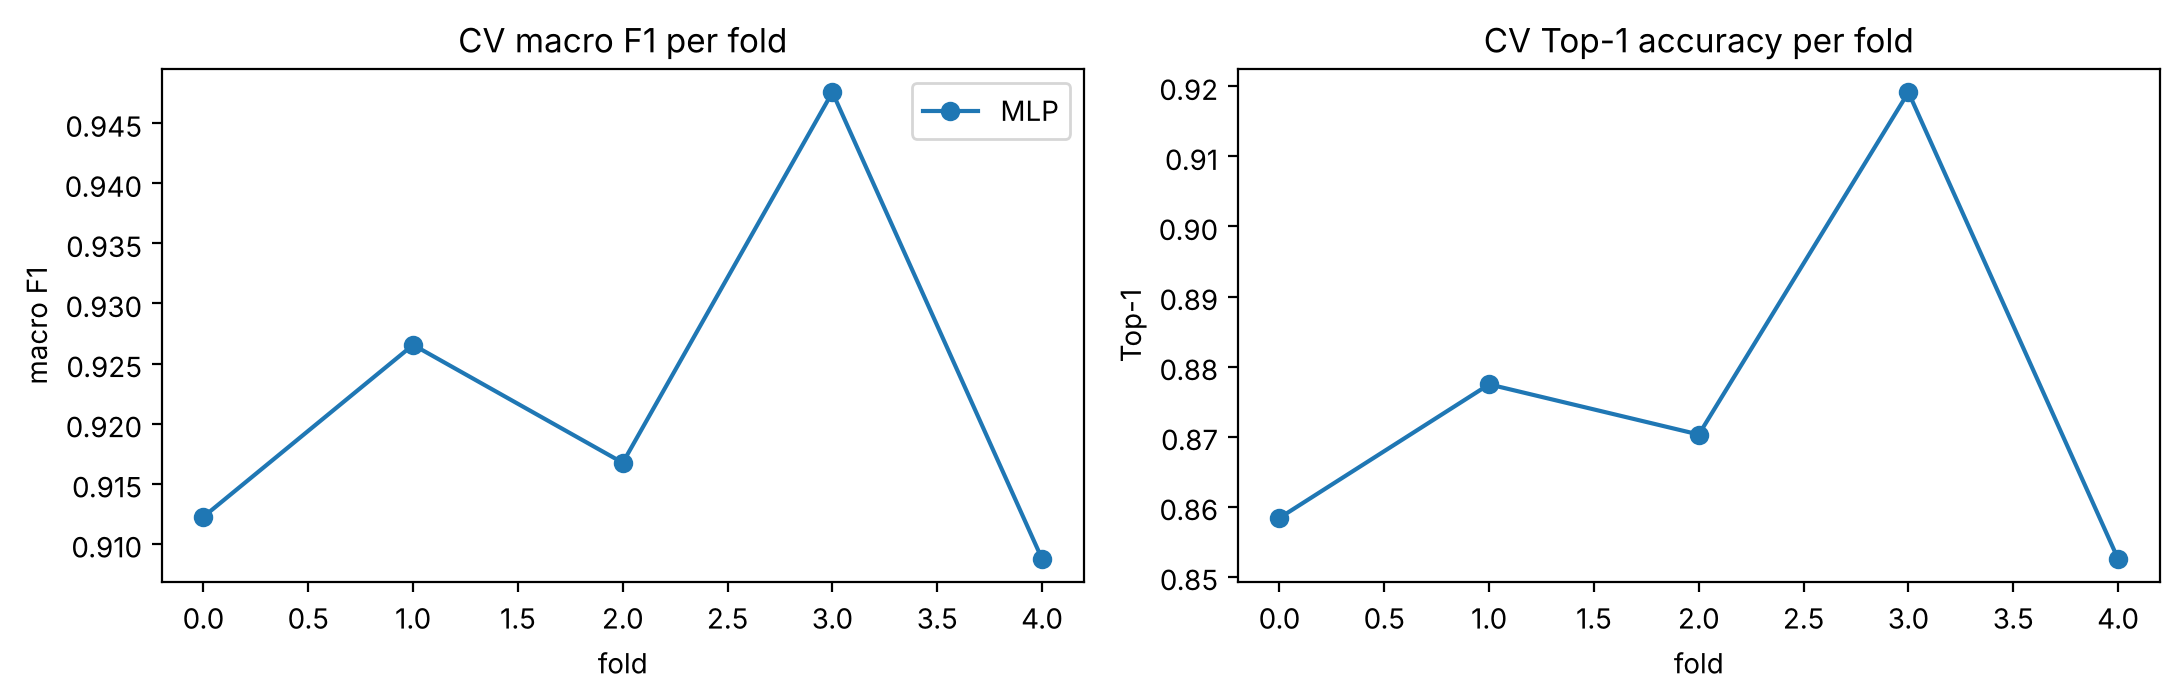

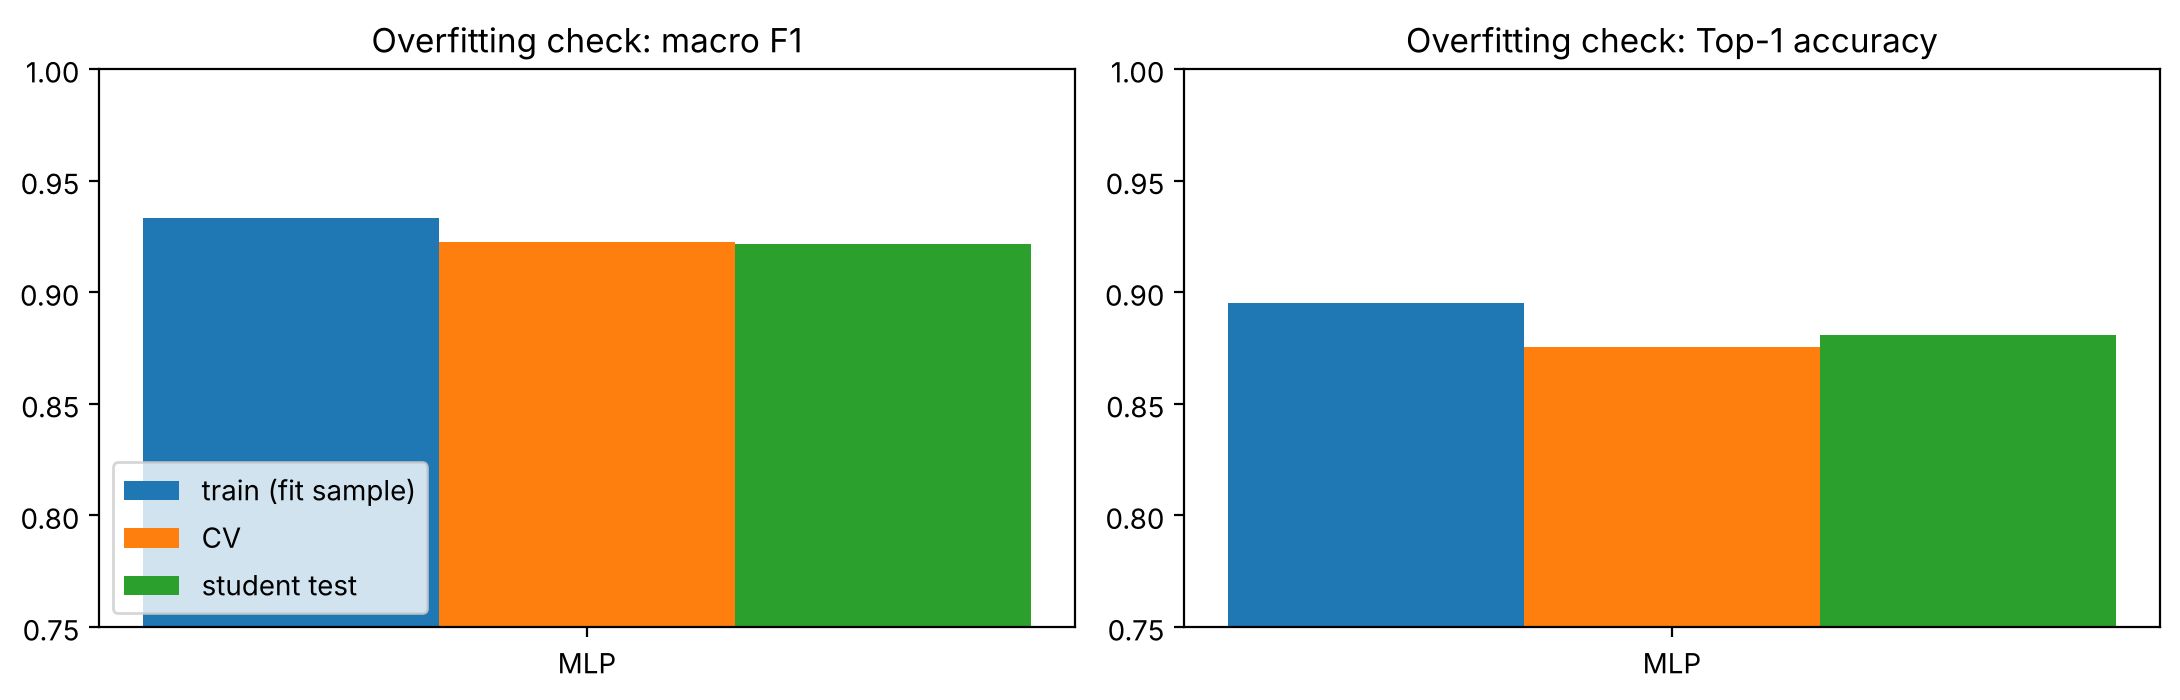

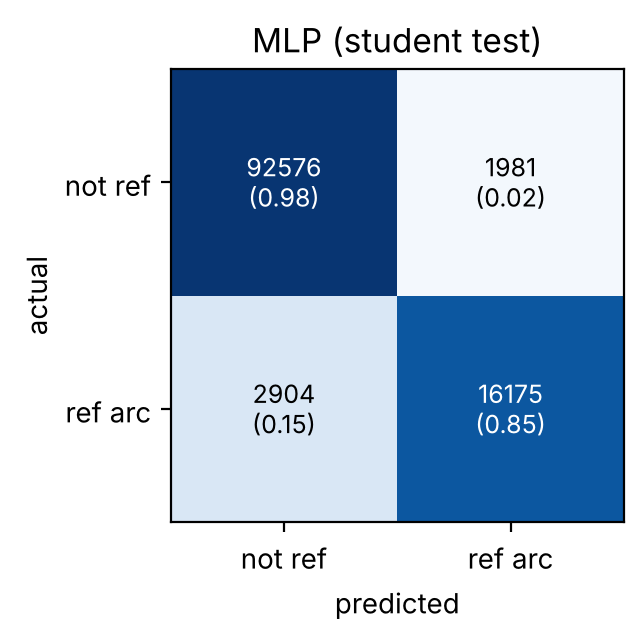

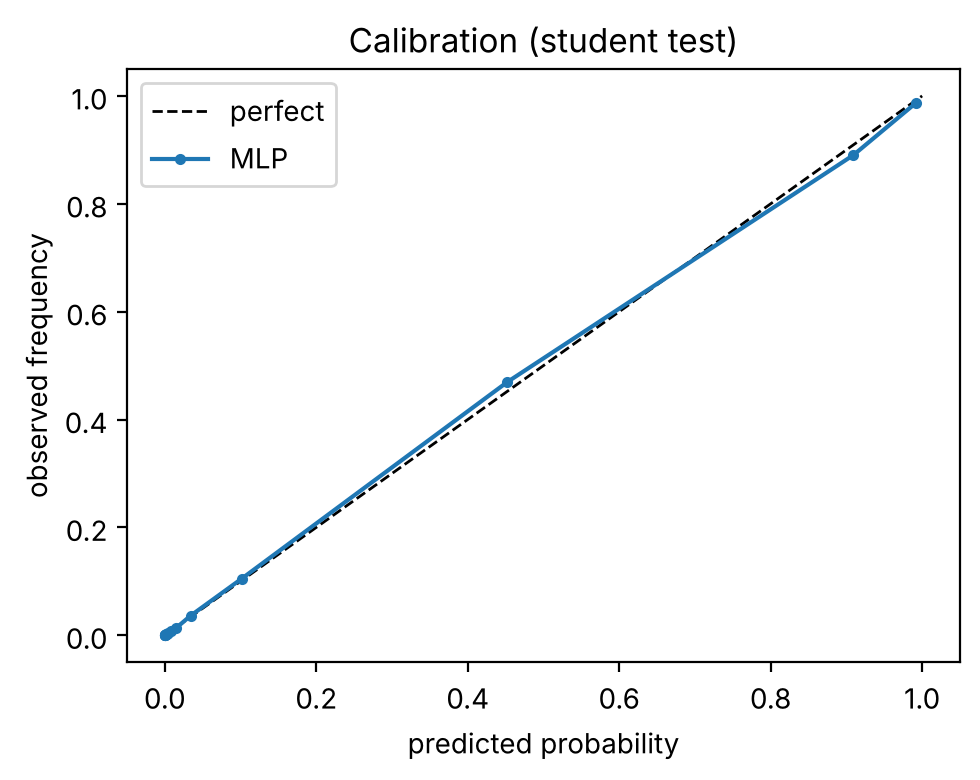

In [8]:
nb.plot_cv_folds({"MLP": cv_mlp})
nb.plot_overfit({"MLP": (train_mlp, cv_mlp, test_mlp)})
nb.plot_confusion({"MLP": test_mlp["confusion"]})
nb.plot_calibration(te.label.to_numpy(), {"MLP": p_mlp})

In [9]:
rows = []
for name, cv, t, h in [("MLP", cv_mlp, test_mlp, hmm_mlp)]:
    rows.append({"model": name, "CV macro F1": cv.macro_f1.mean(), "CV std": cv.macro_f1.std(),
                 "test Top-1": t["top1"], "test macro F1": t["macro_f1"], "test log loss": t["log_loss"],
                 "test continuity": t["continuity"], "Top-1 + HMM (trip mean)": h.hmm_top1.mean(),
                 "route F1 + HMM (trip mean)": h.hmm_route_f1.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV macro F1,CV std,test Top-1,test macro F1,test log loss,test continuity,Top-1 + HMM (trip mean),route F1 + HMM (trip mean)
model,,,,,,,,
MLP,0.9224,0.0156,0.8807,0.9216,0.1134,0.931,0.9296,0.9563
